#LABSHEET 3

##Step 1. Import the required libraries and load a grayscale image for processing.

Saving download (2).png to download (2).png
Image loaded successfully.
Image shape: (350, 286)


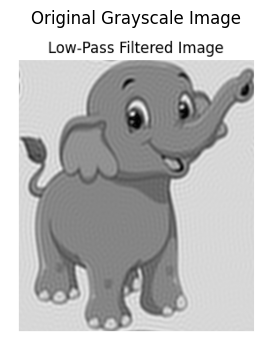

Aman Malik
CU24250099


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Load the image in grayscale
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

# Check whether image is loaded
if img is None:
    print("Error: Image could not be loaded.")
else:
    print("Image loaded successfully.")
    print("Image shape:", img.shape)

    # Display the grayscale image
    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap="gray")
    plt.title("Original Grayscale Image")
    plt.axis("off")
    plt.show()

print("Aman Malik")
print("CU24250099")

##Step 2. Compute the Discrete Fourier Transform (DFT) of the image using OpenCV or NumPy.

In [2]:
# Compute the 2D Discrete Fourier Transform
dft = np.fft.fft2(img)

# Shift the zero-frequency component to the center
dft_shift = np.fft.fftshift(dft)

print("Discrete Fourier Transform computed successfully.")

print("Aman Malik")
print("CU24250099")

Discrete Fourier Transform computed successfully.
Aman Malik
CU24250099


##Step 3. Shift the zero-frequency component to the center of the frequency spectrum for visualization.

In [3]:
# Shift the zero-frequency component to the center
dft_shift = np.fft.fftshift(dft)

print("Zero-frequency component shifted to the center.")

print("Aman Malik")
print("CU24250099")

Zero-frequency component shifted to the center.
Aman Malik
CU24250099


##Step 4. Display and analyze the magnitude spectrum of the transformed image.

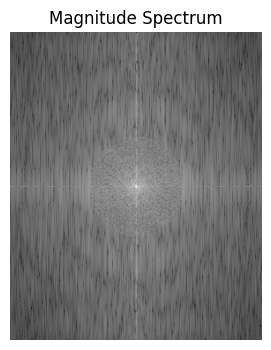

Magnitude spectrum displayed successfully.
Aman Malik
CU24250099


In [4]:
# Calculate magnitude spectrum
magnitude_spectrum = np.abs(dft_shift)

# Use logarithmic transformation for better visualization
magnitude_spectrum = np.log(1 + magnitude_spectrum)

# Display magnitude spectrum
plt.figure(figsize=(6, 4))
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Magnitude Spectrum")
plt.axis("off")
plt.show()

print("Magnitude spectrum displayed successfully.")

print("Aman Malik")
print("CU24250099")

##Step 5. Design and apply a Low-Pass Frequency Filter to suppress high-frequency components and reduce image noise.

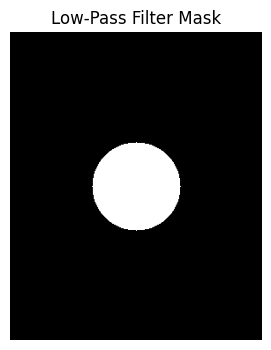

Low-pass frequency filter applied.
Aman Malik
CU24250099


In [5]:
# Get image dimensions
rows, cols = img.shape

# Find the center of the frequency spectrum
crow, ccol = rows // 2, cols // 2

# Create a mask filled with zeros
low_pass_mask = np.zeros((rows, cols), np.uint8)

# Radius of the low-pass filter
radius = 50

# Create circular low-pass mask
cv2.circle(low_pass_mask, (ccol, crow), radius, 1, -1)

# Apply the low-pass filter
low_pass_dft = dft_shift * low_pass_mask

# Display the low-pass filter mask
plt.figure(figsize=(6, 4))
plt.imshow(low_pass_mask, cmap="gray")
plt.title("Low-Pass Filter Mask")
plt.axis("off")
plt.show()

print("Low-pass frequency filter applied.")

print("Aman Malik")
print("CU24250099")

##Step 6. Design and apply a High-Pass Frequency Filter to suppress low-frequency components and enhance edges and fine details.

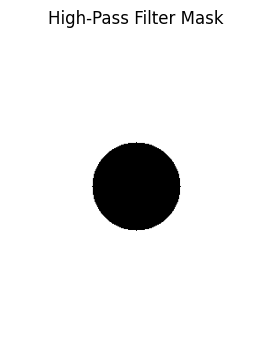

High-pass frequency filter applied.
Aman Malik
CU24250099


In [6]:
# Create a high-pass filter mask
high_pass_mask = np.ones((rows, cols), np.uint8)

# Remove the low-frequency center
cv2.circle(high_pass_mask, (ccol, crow), radius, 0, -1)

# Apply the high-pass filter
high_pass_dft = dft_shift * high_pass_mask

# Display the high-pass filter mask
plt.figure(figsize=(6, 4))
plt.imshow(high_pass_mask, cmap="gray")
plt.title("High-Pass Filter Mask")
plt.axis("off")
plt.show()

print("High-pass frequency filter applied.")

print("Aman Malik")
print("CU24250099")

##Step 7. Perform the Inverse Fourier Transform (IDFT) to reconstruct the filtered images in the spatial domain.

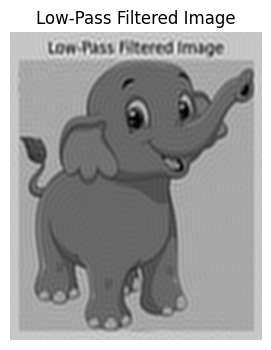

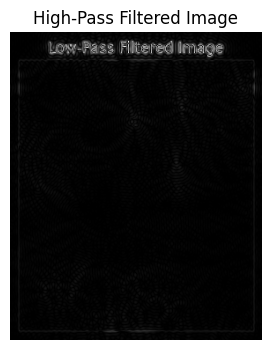

Inverse Fourier Transform completed successfully.
Aman Malik
CU24250099


In [7]:
# Inverse Fourier Transform for Low-Pass filtered image
low_pass_shift = np.fft.ifftshift(low_pass_dft)
low_pass_img = np.fft.ifft2(low_pass_shift)
low_pass_img = np.abs(low_pass_img)

# Inverse Fourier Transform for High-Pass filtered image
high_pass_shift = np.fft.ifftshift(high_pass_dft)
high_pass_img = np.fft.ifft2(high_pass_shift)
high_pass_img = np.abs(high_pass_img)

# Display Low-Pass filtered image
plt.figure(figsize=(6, 4))
plt.imshow(low_pass_img, cmap="gray")
plt.title("Low-Pass Filtered Image")
plt.axis("off")
plt.show()

# Display High-Pass filtered image
plt.figure(figsize=(6, 4))
plt.imshow(high_pass_img, cmap="gray")
plt.title("High-Pass Filtered Image")
plt.axis("off")
plt.show()

print("Inverse Fourier Transform completed successfully.")

print("Aman Malik")
print("CU24250099")

##Step 8. Compare the original image, frequency spectrum, low-pass filtered image, and high-pass filtered image.

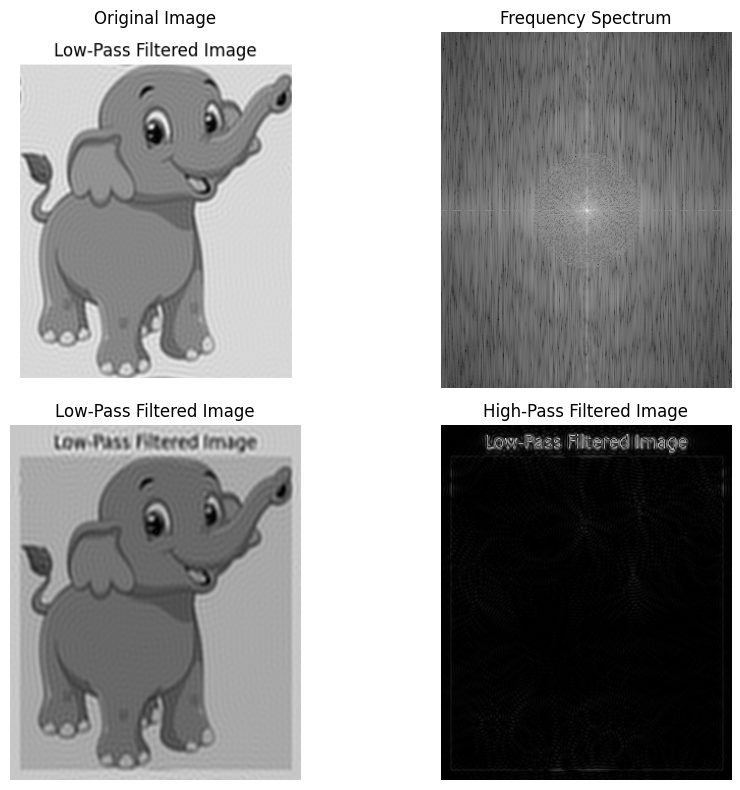

Comparison of original and filtered images completed.
Aman Malik
CU24250099


In [8]:
plt.figure(figsize=(10, 8))

# Original image
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# Magnitude spectrum
plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Frequency Spectrum")
plt.axis("off")

# Low-pass image
plt.subplot(2, 2, 3)
plt.imshow(low_pass_img, cmap="gray")
plt.title("Low-Pass Filtered Image")
plt.axis("off")

# High-pass image
plt.subplot(2, 2, 4)
plt.imshow(high_pass_img, cmap="gray")
plt.title("High-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Comparison of original and filtered images completed.")

print("Aman Malik")
print("CU24250099")

##Step 9. Analyze the impact of frequency domain filtering on image smoothness, edge enhancement, and noise removal.

In [9]:
print("Analysis of Frequency Domain Filtering:")
print()
print("1. Low-Pass Filtering:")
print("   - Makes the image smoother.")
print("   - Reduces high-frequency noise.")
print("   - Removes some fine details and sharp edges.")
print()
print("2. High-Pass Filtering:")
print("   - Enhances edges and fine details.")
print("   - Removes low-frequency background information.")
print("   - Useful for feature and edge detection.")
print()
print("3. Overall Impact:")
print("   - Frequency domain filtering provides direct control")
print("     over different frequency components of an image.")

print()
print("Aman Malik")
print("CU24250099")

Analysis of Frequency Domain Filtering:

1. Low-Pass Filtering:
   - Makes the image smoother.
   - Reduces high-frequency noise.
   - Removes some fine details and sharp edges.

2. High-Pass Filtering:
   - Enhances edges and fine details.
   - Removes low-frequency background information.
   - Useful for feature and edge detection.

3. Overall Impact:
   - Frequency domain filtering provides direct control
     over different frequency components of an image.

Aman Malik
CU24250099


##Step 10. Document the observations and discuss the advantages of frequency domain filtering in practical computer vision applications.

In [10]:
print("Observations:")
print("1. Fourier Transform converts the image from spatial domain")
print("   into frequency domain.")
print("2. Low-pass filtering produces a smoother image and helps")
print("   in reducing high-frequency noise.")
print("3. High-pass filtering enhances edges and fine image details.")
print("4. Frequency domain filtering provides effective control over")
print("   low-frequency and high-frequency components.")
print()
print("Advantages:")
print("1. Useful for image noise reduction.")
print("2. Helps in image enhancement and sharpening.")
print("3. Useful for edge and feature extraction.")
print("4. Can be applied in medical imaging, satellite imaging,")
print("   biometric systems, and other computer vision applications.")
print("5. Different frequency components can be selectively modified.")

print()
print("Aman Malik")
print("CU24250099")

Observations:
1. Fourier Transform converts the image from spatial domain
   into frequency domain.
2. Low-pass filtering produces a smoother image and helps
   in reducing high-frequency noise.
3. High-pass filtering enhances edges and fine image details.
4. Frequency domain filtering provides effective control over
   low-frequency and high-frequency components.

Advantages:
1. Useful for image noise reduction.
2. Helps in image enhancement and sharpening.
3. Useful for edge and feature extraction.
4. Can be applied in medical imaging, satellite imaging,
   biometric systems, and other computer vision applications.
5. Different frequency components can be selectively modified.

Aman Malik
CU24250099
